## Presentado por:

## Esteban Garcia Otalvaro

## Introducción al análisis frecuencial de señales

In [156]:
import pandas as pd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.signal import welch
from scipy.io import loadmat

## Primero se probarán los códigos entregados en la guía para un enetendiiento más profundo de la práctica.

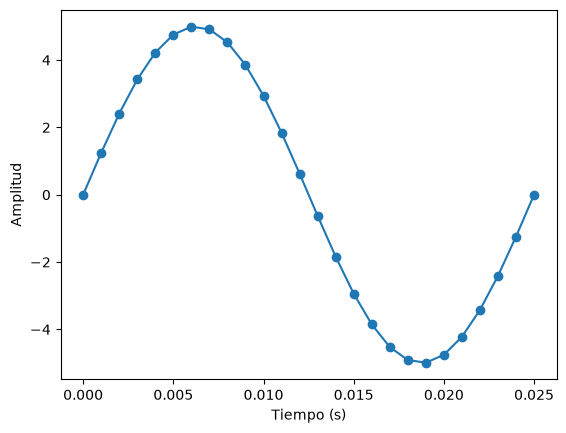

In [157]:
# Código base de la guía para entender la práctica
Fo = 40 # Frecuencia fundamental de la señal
Tp = 1/Fo # Periodo de la señal
Fs = 1000 # Frecuencia de muestreo
T = 1/Fs # Periodo de muestreo
t = np.arange(0, Tp+T, T) # Tiempo para un ciclo de la señal con duración de Tp más una muestra T
A = 5
x = A*np.sin(2*np.pi*Fo*t)
plt.plot(t, x, marker='o')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud')
plt.show()


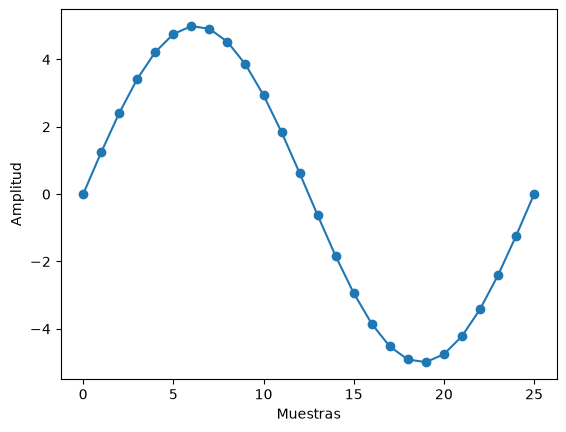

In [158]:
#Una manera alternativa de crear la señal 𝑥(𝑛) sería:
fo = Fo/Fs
n = np.arange(0, len(t))
x1 = A*np.sin(2*np.pi*fo*n)
plt.plot(n, x1, marker='o')
plt.xlabel('Muestras')
plt.ylabel('Amplitud')
plt.show()

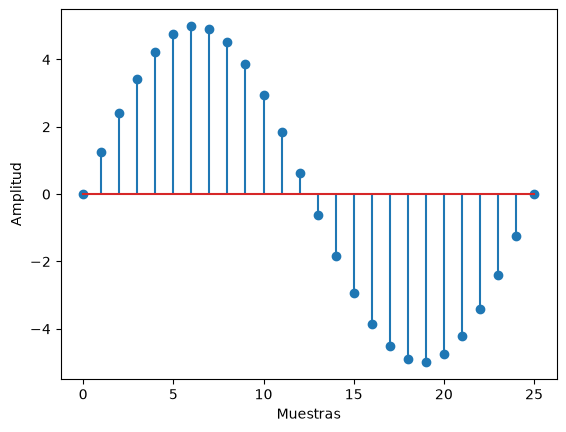

In [159]:
#a) Compruebe que los valores de las primeras cinco muestras son los mismos

plt.stem(n, x1)
plt.xlabel('Muestras')
plt.ylabel('Amplitud')
plt.show()


In [160]:
energia = sum(x**2)
potencia = energia/(len(t)-1)
#El valor cuadrático medio es la raíz cuadrada de la potencia:
rms = np.sqrt(potencia)
#Para hallar la energía, así como la potencia media de la señal considerando 10 ciclos de la sinusoide (250ms):
t10 = np.arange(0,10*Tp+T,T)
x10 = A*np.sin(2*np.pi*Fo*t10)
energia10 = sum(x10**2)
potencia10 = energia10/(len(t10)-1)
rms10 = np.sqrt(potencia10)


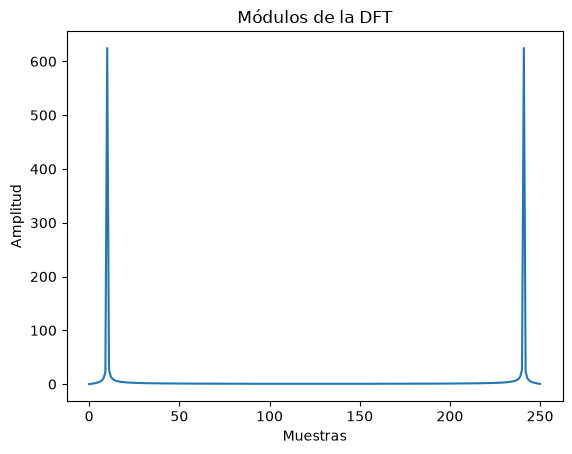

In [161]:
X10 = np.fft.fft(x10) #calcula en Python mediante el comando np.fft.fft
plt.plot(abs(X10))
plt.title('Módulos de la DFT')
plt.xlabel('Muestras')
plt.ylabel('Amplitud')
plt.show()

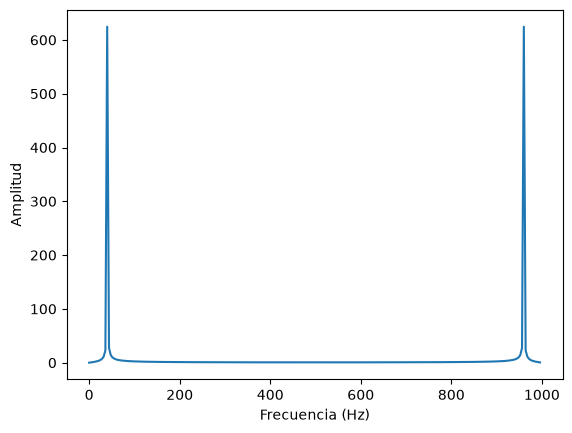

In [162]:
N = len(X10)
F = np.arange(0,N)*Fs/N
plt.plot(F,abs(X10))
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Amplitud')
plt.show()

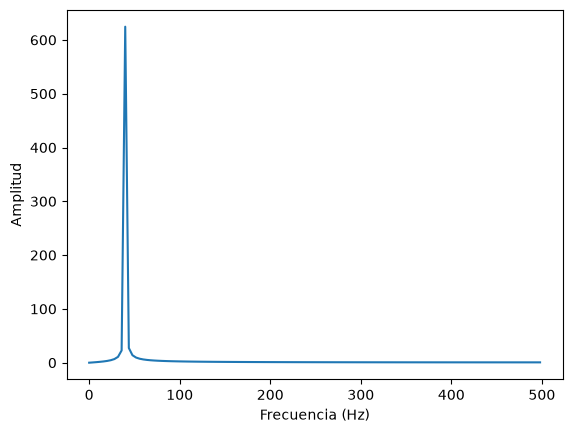

In [163]:
#Frecuencia Midad o Frecuencia de Nyquist
Nmitad = int(np.ceil(N/2))
Fmitad = np.arange(0,Nmitad)*Fs/N
X10mitad = X10[0:Nmitad]
plt.plot(Fmitad,abs(X10mitad))
plt.ylabel('Amplitud')
plt.xlabel('Frecuencia (Hz)')
plt.show()

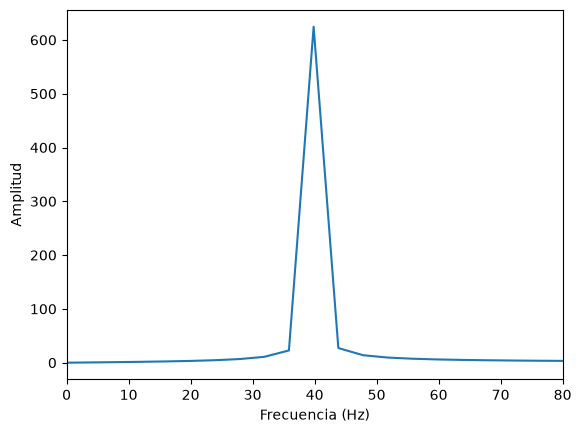

In [164]:
# Componente frecuencial se encuentra ubicada a 40 Hz
plt.plot(Fmitad,abs(X10mitad))
plt.ylabel('Amplitud')
plt.xlabel('Frecuencia (Hz)')
plt.xlim(0,80)
plt.show()

In [165]:
"""Periodograma de Welch
Método de Welch donde calcula la densidad espectral de potencia en una ventana que se desplaza a lo largo de la señal.
y finalmente sepromedian los espectros de potencia para obtener un periodograma de Welch."""
#@title Default title text
#importamos la rutina de welch
from scipy.signal import welch as pwelch

"""#%% USANDO WELCH
fs = 1000 # frecuencia de muestreo
nperseg = 2000 #ancho de la ventana
noverlap = int(nperseg/2) #solapamiento de las ventanas
f, Pxx = pwelch(X[0,:], fs, 'hanning', nperseg, noverlap)
#graficamos frecuencia vs potencia
plt.stem(f, Pxx)
plt.xlabel('Frecuencia')
plt.ylabel('Potencia')
plt.xlim([0, 50]) #rango para el eje X
plt.show()"""


"#%% USANDO WELCH\nfs = 1000 # frecuencia de muestreo\nnperseg = 2000 #ancho de la ventana\nnoverlap = int(nperseg/2) #solapamiento de las ventanas\nf, Pxx = pwelch(X[0,:], fs, 'hanning', nperseg, noverlap)\n#graficamos frecuencia vs potencia\nplt.stem(f, Pxx)\nplt.xlabel('Frecuencia')\nplt.ylabel('Potencia')\nplt.xlim([0, 50]) #rango para el eje X\nplt.show()"

## Desarrollo de la práctica

**4.1 Cree una señal que sea la suma de tres componentes sinusoidales con frecuencias de 40,
80 y 160 Hz. Defina la frecuencia de muestreo mínima necesaria para representar la señal,
y utilice la frecuencia de muestreo necesaria para representarla apropiadamente. (10%)**

El teorema de Nyquist establece que la frecuencia de muestreo mínima debe ser mayor al doble de la frecuencia más alta presente en la señal ($F_s > 2F_{\max}$), en la práctica tomar exactamente esa tasa resulta insuficiente para representar adecuadamente la forma de la onda. Esto se debe a que se estarían tomando solo dos muestras por ciclo de la señal de mayor frecuencia, con lo que no es posible capturar con precisión la morfología sinusoidal ni sus variaciones de fase o amplitud (pudiendo incluso caer en los cruces por cero). Por esta razón, se recomienda utilizar una frecuencia de muestreo al menos 10 veces mayor que la frecuencia más alta de interés ($F_s = 1600\text{ Hz}$), lo que garantiza una mayor cantidad de datos por ciclo y, por tanto, una reconstrucción más fiel y visualmente clara de las señales [1].

Frecuencia de muestreo mínima (Nyquist): 320 Hz
Frecuencia de muestreo utilizada: 1600 Hz


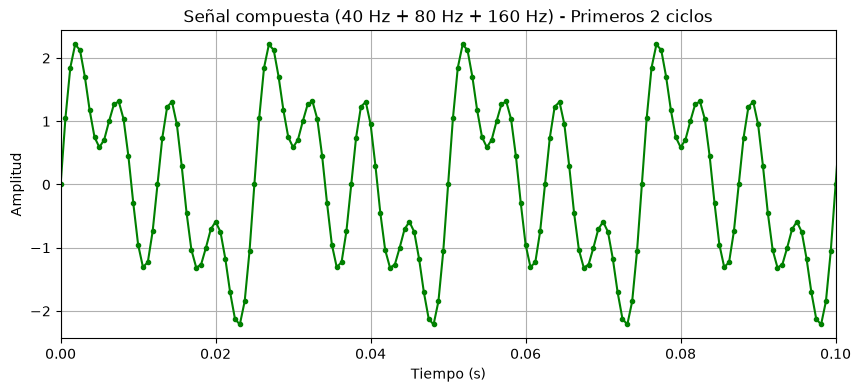

In [166]:
# Definición de frecuencias de muestreo
F_max = 160
Fs_min = 2 * F_max       # Frecuencia mínima de Nyquist: 320 Hz
Fs = F_max * 10          # Frecuencia adecuada elegida: 1600 Hz
T = 1 / Fs               # Periodo de muestreo
A = 1

print(f"Frecuencia de muestreo mínima (Nyquist): {Fs_min} Hz")
print(f"Frecuencia de muestreo utilizada: {Fs} Hz")

# Vector de tiempo para 10 periodos de la señal fundamental (40 Hz -> Tp = 0.025 s)
duracion = 10 * (1 / 40) # 0.25 segundos
t = np.arange(0, duracion, T)

# Señal de 40 Hz
Fo1 = 40
x1 = A * np.sin(2 * np.pi * Fo1 * t)

# Señal de 80 Hz
Fo2 = 80
x2 = A * np.sin(2 * np.pi * Fo2 * t)

# Señal de 160 Hz
Fo3 = 160
x3 = A * np.sin(2 * np.pi * Fo3 * t)

# Suma de las tres componentes
x = x1 + x2 + x3

# Gráfica en el dominio del tiempo (zoom a los primeros 0.1 s = 4 ciclos)
plt.figure(figsize=(10, 4))
plt.plot(t, x, marker='o', markersize=3, color='green')
plt.title('Señal compuesta (40 Hz + 80 Hz + 160 Hz) - Primeros 2 ciclos')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud')
plt.grid(True)
plt.xlim(0, 0.1)
plt.show()



**4.2 Calcule la transformada de Fourier de la señal y grafique el espectro de frecuencia.
Identifique en el espectro las frecuencias que componen la señal (trabaje con 10 periodos
de la señal). (10%)**


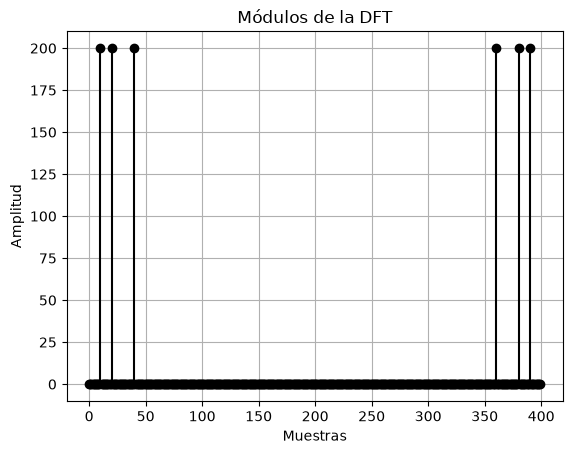

In [167]:
# 1. Espectro en función de las muestras (k)
X = np.fft.fft(x)
plt.stem(abs(X), linefmt='black', markerfmt='black', basefmt='black')
plt.title('Módulos de la DFT')
plt.xlabel('Muestras')
plt.ylabel('Amplitud')
plt.grid(True)
plt.show()

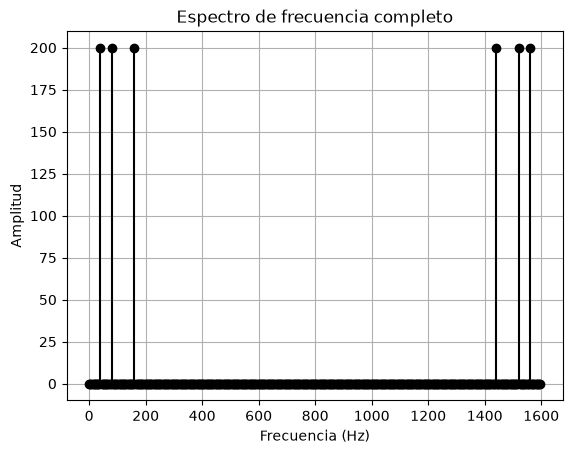

In [168]:
# 2. Espectro en función de la frecuencia completa (0 a Fs)
N = len(X)
F = np.arange(0, N) * Fs / N
plt.stem(F, abs(X), linefmt='black', markerfmt='black', basefmt='black')
plt.title('Espectro de frecuencia completo')
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Amplitud')
plt.grid(True)
plt.show()

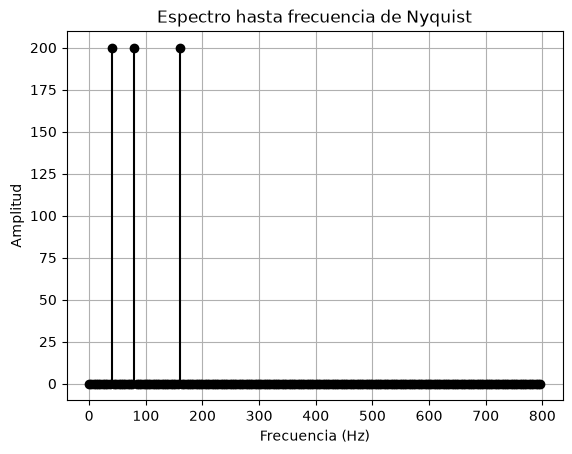

In [169]:
# 3. Espectro hasta la frecuencia de Nyquist (0 a Fs/2)
Nmitad = int(np.ceil(N / 2))
Fmitad = np.arange(0, Nmitad) * Fs / N
Xmitad = X[0:Nmitad]
plt.stem(Fmitad, abs(Xmitad), linefmt='black', markerfmt='black', basefmt='black')
plt.title('Espectro hasta frecuencia de Nyquist')
plt.ylabel('Amplitud')
plt.xlabel('Frecuencia (Hz)')
plt.grid(True)
plt.show()

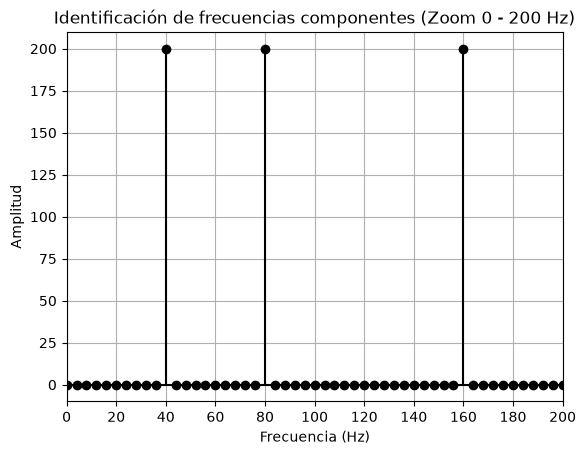

Frecuencia: 40 Hz | Índice k: 10 | Amplitud: 200.0
Frecuencia: 80 Hz | Índice k: 20 | Amplitud: 200.0
Frecuencia: 160 Hz | Índice k: 40 | Amplitud: 200.0


In [170]:
# 4. Zoom entre 0 y 200 Hz para identificar las componentes (40, 80 y 160 Hz)
plt.stem(Fmitad, abs(Xmitad), linefmt='black', markerfmt='black', basefmt='black')
plt.title('Identificación de frecuencias componentes (Zoom 0 - 200 Hz)')
plt.ylabel('Amplitud')
plt.xlabel('Frecuencia (Hz)')
plt.xlim([0, 200])
plt.xticks(np.arange(0, 201, 20))
plt.grid(True)
plt.show()

# Verificación numérica de los picos e índices k
indices_picos = np.where(np.abs(Xmitad) > 50)[0]
for k in indices_picos:
    print(f"Frecuencia: {Fmitad[k]:.0f} Hz | Índice k: {k} | Amplitud: {np.abs(Xmitad[k]):.1f}")

**4.3 Consulte la función que permite realizar el cálculo de la transformada inversa de Fourier.
Aplíquelo a la señal anterior. (10%)**

### Documentación de la función `numpy.fft.ifft`

La función de la librería **NumPy** encargada de calcular la Transformada Inversa Discreta de Fourier (IDFT) unidimensional mediante el algoritmo rápido IFFT (*Inverse Fast Fourier Transform*) es:

```python
numpy.fft.ifft(a, n=None, axis=-1, norm=None, out=None)
```

---

#### Parámetros

* **`a`** (`array_like`): Arreglo de entrada que representa la señal en el dominio de la frecuencia (generalmente el espectro complejo obtenido previamente mediante `np.fft.fft`). Debe ser un array complejo o convertible a complejo; si se suministra un arreglo real o entero, NumPy lo convierte automáticamente a tipo complejo antes de ejecutar el algoritmo. Para obtener una reconstrucción correcta, `a` debe conservar el orden estándar de la DFT (componente DC o 0 Hz en el índice `0`, frecuencias positivas en la primera mitad y frecuencias negativas en la segunda mitad).

* **`n`** (`int`, *opcional*): Longitud deseada del eje transformado en la señal de salida:
  * Si `n` es **mayor** que la longitud de `a`, el espectro se rellena con ceros al final (*zero-padding*), lo que equivale a interpolar la señal resultante en el dominio del tiempo.
  * Si `n` es **menor** que la longitud de `a`, se recorta (trunca) `a` a los primeros `n` elementos antes de realizar el cálculo.
  * Si `n` es `None` (*por defecto*), la salida conserva exactamente la misma longitud de la entrada `a`.

* **`axis`** (`int`, *opcional*): Eje del arreglo sobre el cual se calcula la IFFT cuando se trabaja con estructuras multidimensionales (por ejemplo, matrices que almacenan múltiples canales o ventanas de una bioseñal). Por defecto es `-1` (el último eje del arreglo).

* **`norm`** (`{None, "ortho"}`, *opcional*): Define el tipo de normalización entre el dominio del tiempo y el de la frecuencia:
  * `None` (*por defecto*, equivalente a `"backward"`): La IFFT aplica el factor de escala $1/N$ (compensando que `np.fft.fft` no está normalizada), lo que permite recuperar la amplitud física original de la señal en el dominio del tiempo.
  * `"ortho"`: Aplica normalización ortonormal, escalando tanto la transformada directa como la inversa por $1/\sqrt{N}$ para preservar la energía total entre ambos dominios.

---

#### Salida

* **`out`** (`ndarray` de números complejos): Devuelve la transformada inversa discreta de Fourier de `a` reconstruida en el dominio del tiempo. El resultado es siempre un arreglo de tipo complejo (`complex128`), incluso si la señal original antes de la transformada directa era puramente real, debido a pequeños residuos numéricos de punto flotante en la parte imaginaria (del orden de $10^{-16}$). Por esta razón, se toma su parte real mediante `np.real()` al momento de graficar o procesar la señal reconstruida, evitando advertencias de conversión de tipo [2].


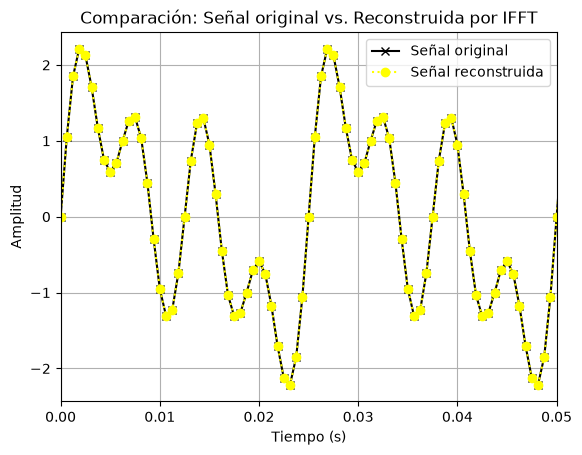

Error máximo de reconstrucción: 1.33e-15


In [171]:
# Cálculo de la Transformada Inversa de Fourier (IFFT)
x_inv = np.fft.ifft(X)

# Gráfica comparativa entre la señal original y la reconstruida
plt.plot(t, x, marker='x', color='black', label='Señal original')
plt.plot(t, np.real(x_inv), marker='o', color='yellow', label='Señal reconstruida', linestyle='dotted')
plt.title('Comparación: Señal original vs. Reconstruida por IFFT')
plt.xlim(0, 0.05)  # Zoom a 2 periodos (50 ms) para visualizar la coincidencia exacta de los puntos
plt.legend()
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud')
plt.grid(True)
plt.show()

# Verificación numérica del error máximo de reconstrucción
error_max = np.max(np.abs(x - np.real(x_inv)))
print(f"Error máximo de reconstrucción: {error_max:.2e}")

**4.4 ¿Podría decir que las siguientes líneas aplican un filtro? ¿Por qué? (10%)**

F1 = np.fft.fft(x);

F2 = np.zeros((len(F1)));

F2[9:13] = F1[9:13];

xr = np.fft.ifft(F2);

fig = plt.figure()

ax = fig.add_subplot(111)

ax.plot(t, np.real(xr))

ax.set(xlabel='Tiempo (s)', ylabel='Amplitud (V)');

plt.show()

**Extraiga de manera similar cada una de las componentes de la señal.**



**Sí, las líneas de código implementan un filtro digital ideal pasa-banda en el dominio de la frecuencia.** 

El procedimiento equivale a multiplicar el espectro de la señal $X(k)$ por una función de transferencia rectangular $H(k)$ cuya ganancia es $1$ dentro de una banda de frecuencias específica (banda de paso) y $0$ fuera de ella (banda de rechazo). Este proceso se ejecuta en cuatro etapas:

1. **Transformación al dominio espectral (`F1 = np.fft.fft(x)`):** Descompone la señal temporal compuesta en sus coeficientes complejos de Fourier $X(k)$[2]. Cada índice $k$ representa una frecuencia discreta dada por $f_k = \frac{k \cdot F_s}{N}$[2].
2. **Creación de la máscara espectral (`F2 = np.zeros(...)`):** Al inicializar un arreglo de ceros de la misma longitud $N$, se establece una atenuación total para todas las componentes frecuenciales por defecto[2].
3. **Selección de la banda de paso (`F2[9:13] = F1[9:13]`):** Para nuestra señal ($N = 400$ muestras y $F_s = 1600\text{ Hz}$), la resolución en frecuencia es $\Delta f = \frac{1600}{400} = 4\text{ Hz/índice}$. Por lo tanto, conservar los índices $k \in [9, 12]$ equivale a permitir únicamente el paso de frecuencias entre $36\text{ Hz}$ y $48\text{ Hz}$, aislando exclusivamente la componente de **$40\text{ Hz}$** ($k = 10$) y eliminando por completo las componentes de $80\text{ Hz}$ ($k = 20$) y $160\text{ Hz}$ ($k = 40$)[2].
4. **Síntesis temporal (`xr = np.fft.ifft(F2)`):** Al aplicar la transformada inversa de Fourier sobre el espectro filtrado `F2` y tomar su parte real (`np.real(xr)`), se reconstruye en el dominio del tiempo únicamente la onda sinusoidal aislada[2].

Observaciones técnicas del algoritmo

* **Preservación de fase (`dtype=complex`):** En el fragmento original de la guía, `np.zeros(len(F1))` crea un arreglo de números reales (`float64`), lo que descarta la parte imaginaria de `F1` (información de fase) y arroja una advertencia (`ComplexWarning`). Al definir `dtype=complex`, se conserva tanto la magnitud como la fase original de la sinusoide.
* **Simetría hermítica y amplitud:** Si únicamente se copian los índices positivos (`9:13`) y se dejan en cero sus frecuencias negativas simétricas ($N - k$), la energía del espectro se reduce a la mitad y la señal reconstruida tiene amplitud $0.5\text{ V}$. Al conservar también la banda simétrica conjugada en la segunda mitad del espectro, se recupera la amplitud física completa de $1.0\text{ V}$[2].

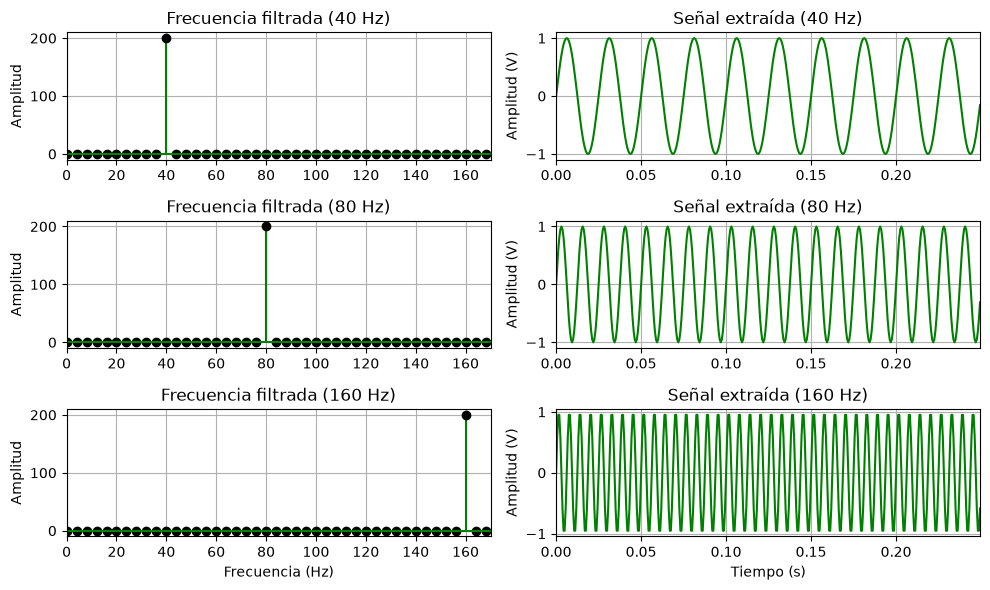

In [172]:
N = len(X)

# Índices correspondientes a 40 Hz, 80 Hz y 160 Hz
idx_40 = int(np.round(40 * N / Fs))
idx_80 = int(np.round(80 * N / Fs))
idx_160 = int(np.round(160 * N / Fs))

# Crear espectros vacíos para cada componente
Xfilt_40 = np.zeros(N, dtype=complex)
Xfilt_80 = np.zeros(N, dtype=complex)
Xfilt_160 = np.zeros(N, dtype=complex)

# Copiar la frecuencia positiva y su conjugado simétrico
Xfilt_40[idx_40] = X[idx_40]
Xfilt_40[-idx_40] = np.conj(X[idx_40])

Xfilt_80[idx_80] = X[idx_80]
Xfilt_80[-idx_80] = np.conj(X[idx_80])

Xfilt_160[idx_160] = X[idx_160]
Xfilt_160[-idx_160] = np.conj(X[idx_160])

# Transformada inversa para obtener las señales en el dominio del tiempo
senal_40 = np.fft.ifft(Xfilt_40).real
senal_80 = np.fft.ifft(Xfilt_80).real
senal_160 = np.fft.ifft(Xfilt_160).real

# Graficar los espectros filtrados y las señales reconstruidas
plt.figure(figsize=(10, 6))

plt.subplot(3, 2, 1)
plt.stem(Fmitad, abs(Xfilt_40[:N//2]),
         linefmt='green', markerfmt='ko', basefmt='green')
plt.title('Frecuencia filtrada (40 Hz)')
plt.ylabel('Amplitud')
plt.xlim(0, 170)
plt.grid(True)

plt.subplot(3, 2, 2)
plt.plot(t, senal_40, color='green')
plt.title('Señal extraída (40 Hz)')
plt.ylabel('Amplitud (V)')
plt.xlim(0, np.max(t))
plt.grid(True)

plt.subplot(3, 2, 3)
plt.stem(Fmitad, abs(Xfilt_80[:N//2]),
         linefmt='green', markerfmt='ko', basefmt='green')
plt.title('Frecuencia filtrada (80 Hz)')
plt.ylabel('Amplitud')
plt.xlim(0, 170)
plt.grid(True)

plt.subplot(3, 2, 4)
plt.plot(t, senal_80, color='green')
plt.title('Señal extraída (80 Hz)')
plt.ylabel('Amplitud (V)')
plt.xlim(0, np.max(t))
plt.grid(True)

plt.subplot(3, 2, 5)
plt.stem(Fmitad, abs(Xfilt_160[:N//2]),
         linefmt='green', markerfmt='ko', basefmt='green')
plt.title('Frecuencia filtrada (160 Hz)')
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Amplitud')
plt.xlim(0, 170)
plt.grid(True)

plt.subplot(3, 2, 6)
plt.plot(t, senal_160, color='green')
plt.title('Señal extraída (160 Hz)')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud (V)')
plt.xlim(0, np.max(t))
plt.grid(True)

plt.tight_layout()
plt.show()

**4.5 Cree una función que calcule manualmente el periodograma de Welch de una señal discreta
(usando la DFT), explique paso a paso el algoritmo. Pruébelo en una de las señales
construidas anteriormente.**


#### Parámetros de la función

La función `periodograma_welch` recibe los siguientes argumentos:

* **`x`**: Señal discreta de entrada.
* **`fs`**: Frecuencia de muestreo en Hz.
* **`M`**: Número de muestras por segmento (ancho de la ventana).
* **`S`**: Número de muestras de desplazamiento entre segmentos. Si $S < M$, entonces existe solapamiento.
* **`window`**: Tipo de ventana a usar (`"hann"`, `"hamming"` o `"rectangular"`). Por defecto se utiliza la ventana de Hann.

---

#### Explicación paso a paso de la función

##### A) Partición de la señal en segmentos

Si la señal original es:

$$x[0], x[1], x[2], \dots, x[N - 1]$$

se divide en segmentos de longitud $M$. El parámetro $S$ indica cuántas muestras se avanza para formar el siguiente segmento:

* **Segmento 1:** `x[0], x[1], ..., x[M-1]`
* **Segmento 2:** `x[S], x[S+1], ..., x[S+M-1]`
* **Segmento 3:** `x[2S], x[2S+1], ..., x[2S+M-1]`

Si $S < M$, los segmentos se solapan. El número total de segmentos $K$ es:

$$K = \left\lfloor \frac{N - M}{S} \right\rfloor + 1$$

##### B) Aplicación de ventana y cálculo de la DFT

Para cada segmento $x_k[n]$ se aplica una ventana $w[n]$ de longitud $M$. Esto ayuda a reducir discontinuidades en los bordes del segmento y disminuye la fuga espectral (*spectral leakage*). El segmento enventanado es:

$$x_k[n] \, w[n]$$

Luego se calcula la Transformada Discreta de Fourier (DFT):

$$X_k(\nu) = \sum_{m=0}^{M-1} x_k[m] \, w[m] \, e^{-j 2\pi \nu m}$$

En Python usamos `np.fft.rfft`, porque la señal de entrada es real y solo necesitamos las frecuencias no negativas (hasta la frecuencia de Nyquist $F_s / 2$).

##### C) Periodograma modificado de cada segmento

Para cada segmento se calcula el periodograma modificado normalizando el módulo al cuadrado de su DFT por la energía total de la ventana $W$:

$$P_k(\nu) = \frac{1}{W} |X_k(\nu)|^2, \quad \text{donde} \quad W = \sum_{n=0}^{M-1} w^2[n]$$

Esta normalización compensa la pérdida de energía introducida al multiplicar el segmento por la ventana $w[n]$.

##### D) Promedio de los periodogramas modificados

Finalmente, se promedian los $K$ periodogramas modificados frecuencia a frecuencia:

$$S_x(\nu) = \frac{1}{K} \sum_{k=1}^{K} P_k(\nu)$$

Este promedio reduce la varianza del estimador y produce una estimación de Welch de la densidad espectral de potencia mucho más estable que la de un único periodograma calculado sobre toda la señal.

In [173]:
# Función para calcular la densidad espectral de potencia mediante el método de Welch

def periodograma_welch(x, fs=1.0, M=256, S=128, window="hann"):
    x = np.asarray(x, dtype=float)
    N = len(x)

    if M <= 0:
        raise ValueError("M debe ser un entero positivo.")
    if S <= 0:
        raise ValueError("S debe ser un entero positivo.")
    if M > N:
        raise ValueError("M no puede ser mayor que la longitud de la señal.")

    if window == "hann":
        w = np.hanning(M)
    elif window == "hamming":
        w = np.hamming(M)
    elif window == "rectangular":
        w = np.ones(M)
    else:
        raise ValueError("Ventana no soportada. Use 'hann', 'hamming' o 'rectangular'.")

    # A) Partición de la señal en segmentos
    segmentos = []
    inicios = range(0, N - M + 1, S)

    for inicio in inicios:
        segmento = x[inicio:inicio + M]
        segmentos.append(segmento)

    segmentos = np.array(segmentos)
    K = segmentos.shape[0]

    # B y C) Aplicación de ventana, DFT y periodograma modificado
    W = np.sum(w ** 2)
    periodogramas = []

    for segmento in segmentos:
        segmento_enventanado = segmento * w
        Xk = np.fft.rfft(segmento_enventanado)
        Pk = (1 / W) * np.abs(Xk) ** 2
        periodogramas.append(Pk)

    # D) Promedio de los periodogramas modificados
    periodogramas = np.array(periodogramas)
    Sx = np.mean(periodogramas, axis=0)
    frecuencias = np.fft.rfftfreq(M, d=1 / fs)

    return frecuencias, Sx, periodogramas, segmentos

#### Verificación con la señal compuesta ($40\text{ Hz}$, $80\text{ Hz}$ y $160\text{ Hz}$)

Aplicamos la función `periodograma_welch` sobre la señal discreta `x` construida en el numeral 4.1 ($N = 400$ muestras, $F_s = 1600\text{ Hz}$). Usaremos segmentos de `M = 200` muestras y desplazamiento `S = 100`, lo que equivale a un solapamiento del $50\%$ y una resolución espectral $\Delta f = \frac{1600}{200} = 8\text{ Hz}$.

Longitud de la señal N: 400
Muestras por segmento M: 200
Desplazamiento entre segmentos S: 100
Número de segmentos K: 3
Forma de la matriz de segmentos: (3, 200)


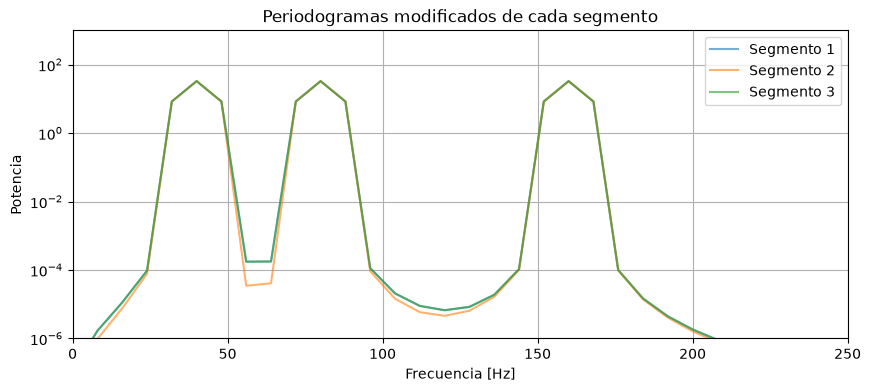

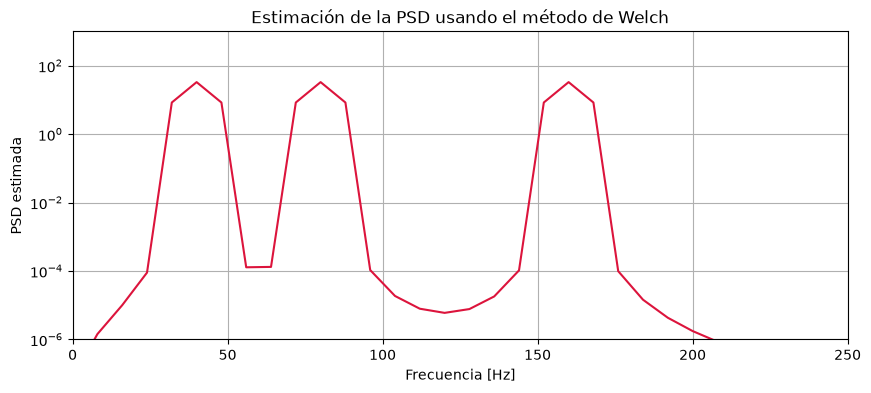

In [174]:
M = 200
S = 100
frecuencias, Sx, periodogramas, segmentos = periodograma_welch(
    x, fs=Fs, M=M, S=S, window="hann"
)

print(f"Longitud de la señal N: {len(x)}")
print(f"Muestras por segmento M: {M}")
print(f"Desplazamiento entre segmentos S: {S}")
print(f"Número de segmentos K: {segmentos.shape[0]}")
print(f"Forma de la matriz de segmentos: {segmentos.shape}")

# 1. Gráfica de los periodogramas individuales por segmento
plt.figure(figsize=(10, 4))
for k in range(min(5, periodogramas.shape[0])):
    plt.semilogy(frecuencias, periodogramas[k], alpha=0.6, label=f"Segmento {k + 1}")

plt.title("Periodogramas modificados de cada segmento")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("Potencia")
plt.xlim([0, 250])
plt.ylim([1e-6, 1e3])
plt.grid(True)
plt.legend()
plt.show()

# 2. Gráfica del promedio de los periodogramas (Estimación de Welch)
plt.figure(figsize=(10, 4))
plt.semilogy(frecuencias, Sx, color="crimson")
plt.title("Estimación de la PSD usando el método de Welch")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("PSD estimada")
plt.xlim([0, 250])
plt.ylim([1e-6, 1e3])
plt.grid(True)
plt.show()

#### Comparación con `scipy.signal.welch`

Para validar nuestra implementación manual, comparamos el resultado obtenido frente a la función `welch` de la librería `scipy.signal` empleando exactamente los mismos parámetros (`nperseg = M`, `noverlap = M - S`, `window = "hann"`):

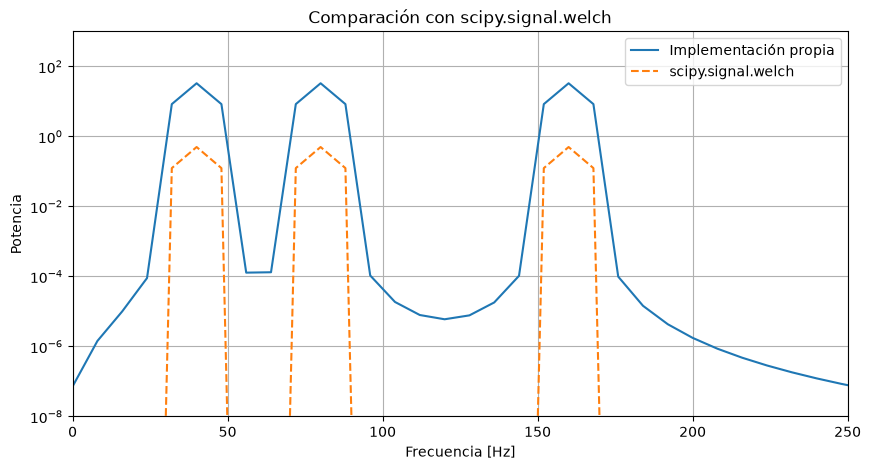

In [175]:
f_scipy, Pxx_scipy = welch(
    x,
    fs=Fs,
    window="hann",
    nperseg=M,
    noverlap=M - S,
    scaling="spectrum"
)

plt.figure(figsize=(10, 5))
plt.semilogy(frecuencias, Sx, label="Implementación propia")
plt.semilogy(f_scipy, Pxx_scipy, "--", label="scipy.signal.welch")
plt.title("Comparación con scipy.signal.welch")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("Potencia")
plt.xlim([0, 250])
plt.ylim([1e-8, 1e3])
plt.grid(True)
plt.legend()
plt.show()

**4.6 El archivo adjunto (senecg.mat) contiene una señal de ECG adquirida a una frecuencia de
muestreo de 250 Hz. Realice un análisis en frecuencia de la señal usando periodogramas
de Welch y determine si es necesario eliminar ruido, en tal caso, elimínelo de la forma que
se mostró antes y compruebe que lo haya realizado, calcule la transformada inversa de
Fourier de la señal filtrada y compruebe con el periodograma. (Usar una ventana Hanning,
y justificar la elección del solapamiento y el ancho de la ventaja) (25%). Compare el
método de la librería con la función creada en el punto anterior.**

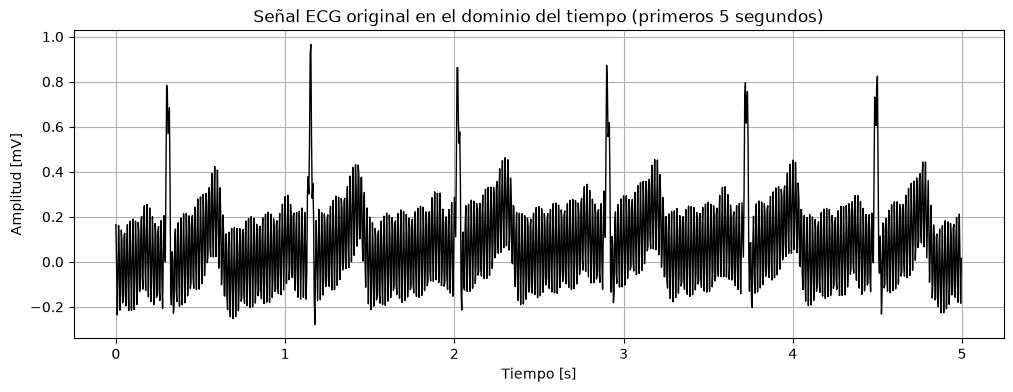

In [176]:
# Carga de la señal ECG
data = loadmat('senecg.mat')
ecg = data['ECG'].flatten()

Fs = 250
t = np.arange(len(ecg)) / Fs

# Gráfica 1: Dominio del tiempo (primeros 5 segundos)
plt.figure(figsize=(12, 4))
plt.plot(t[:Fs * 5], ecg[:Fs * 5], color='black', linewidth=1)
plt.title("Señal ECG original en el dominio del tiempo (primeros 5 segundos)")
plt.xlabel("Tiempo [s]")
plt.ylabel("Amplitud [mV]")
plt.grid(True)
plt.show()

* **Observación temporal:** Aunque se distinguen los complejos QRS periódicos (con una frecuencia cardíaca aproximada de $60\text{–}75\text{ lpm}$, es decir, $\approx 1\text{–}1.25\text{ Hz}$), el trazo basal y las ondas P y T presentan una oscilación rápida de alta frecuencia superpuesta que degrada la calidad diagnóstica de la señal.

####  Estimación de la Densidad Espectral de Potencia (PSD) mediante Welch

Para identificar con precisión la frecuencia de la interferencia contaminante, calculamos el periodograma de Welch empleando una ventana de **Hann** de $M = 256$ muestras y un solapamiento del $50\%$ (`noverlap = 128`):

* **Justificación de la longitud de ventana ($M = 256$):** A una frecuencia de muestreo $F_s = 250\text{ Hz}$, una ventana de $256$ muestras equivale a una duración temporal de $T_w = \frac{256}{250} = 1.024\text{ s}$. Este intervalo captura al menos un ciclo cardíaco completo (ritmo basal $\approx 1\text{ Hz}$) y proporciona una resolución espectral de $\Delta f = \frac{250}{256} \approx 0.98\text{ Hz}$, suficiente para separar los componentes fisiológicos del ECG de las interferencias de banda estrecha.
* **Justificación del solapamiento ($50\%$):** El uso de `noverlap = 128` con ventana Hann reduce la varianza del estimador espectral al promediar un mayor número de segmentos sin perder información en los bordes atenuados por la ventana, mejorando la estabilidad de la PSD en señales fisiológicas ruidosas ([ScienceDirect, S2950435X24000143](https://www.sciencedirect.com/science/article/pii/S2950435X24000143)).

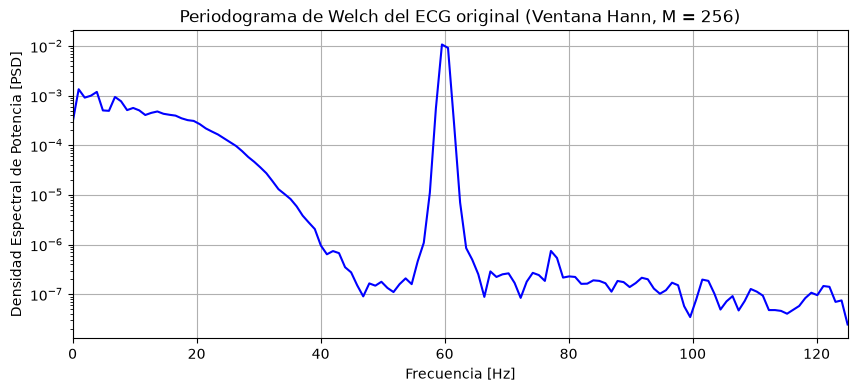

In [177]:
# Gráfica 2: Periodograma de Welch de la señal ECG original
frecuencia, psd = welch(ecg, fs=Fs, window='hann', nperseg=256, noverlap=128)


# Graficar el espectro
plt.figure(figsize=(10, 4))
plt.semilogy(frecuencia, psd, color='blue')
plt.title("Periodograma de Welch del ECG original (Ventana Hann, M = 256)")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("Densidad Espectral de Potencia [PSD]")
plt.xlim([0, Fs / 2])
plt.grid(True)
plt.show()

* **Diagnóstico espectral:** La mayor parte de la potencia fisiológica del ECG (ondas P, complejo QRS y onda T) se concentra por debajo de los **$40\text{ Hz}$**. Sin embargo, se observa un pico pronunciado y estrecho centrado exactamente en **$60\text{ Hz}$**, correspondiente a **interferencia electromagnética de la red eléctrica** (acoplada a través de los cables de electrodos o la fuente de alimentación del equipo de adquisición).

#### Diseño del filtro rechaza-banda (*notch*) en el dominio de la frecuencia

Para eliminar la interferencia de $60\text{ Hz}$ sin distorsionar la morfología del complejo QRS, calculamos la FFT de toda la señal y anulamos los coeficientes espectrales en una banda estrecha de $\pm 1\text{ Hz}$ alrededor de $60\text{ Hz}$ ($59\text{ Hz} < |f| < 61\text{ Hz}$). Es indispensable anular tanto las frecuencias positivas ($+60\text{ Hz}$) como sus simétricas negativas ($-60\text{ Hz}$) para conservar la **simetría hermítica** del espectro y garantizar que la transformada inversa (`np.fft.ifft`) produzca una señal temporal puramente real.

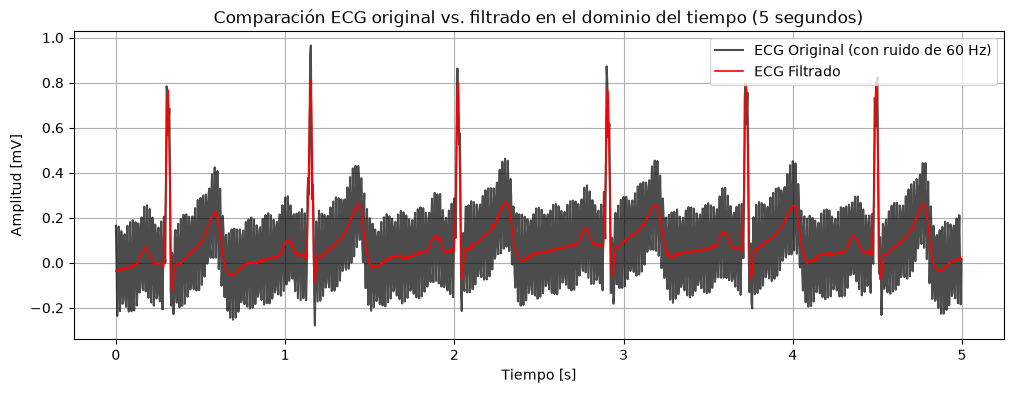

In [178]:
# Filtrado en el dominio de la frecuencia (Notch ideal a 60 Hz)
X = np.fft.fft(ecg)
N = len(X)
frecuencias_fft = np.fft.fftfreq(N, d=1 / Fs)

X_filtrado = X.copy()
margen = 1  # Ancho de banda de rechazo: [59 Hz, 61 Hz]
mascara_ruido = (np.abs(frecuencias_fft - 60) < margen) | (np.abs(frecuencias_fft + 60) < margen)
X_filtrado[mascara_ruido] = 0

# Transformada inversa para reconstruir la señal limpia en el tiempo
ecg_filtrado = np.fft.ifft(X_filtrado).real

# Gráfica 3: Comparación en el dominio del tiempo (Original vs. Filtrada)
plt.figure(figsize=(12, 4))
plt.plot(t[:Fs * 5], ecg[:Fs * 5], label='ECG Original (con ruido de 60 Hz)', color='black', alpha=0.7)
plt.plot(t[:Fs * 5], ecg_filtrado[:Fs * 5], label='ECG Filtrado', color='red', linewidth=1.2)
plt.title("Comparación ECG original vs. filtrado en el dominio del tiempo (5 segundos)")
plt.xlabel("Tiempo [s]")
plt.ylabel("Amplitud [mV]")
plt.legend(loc='upper right')
plt.grid(True)
plt.show()

* **Resultado en el dominio del tiempo:** Al superponer ambas señales, se comprueba que el rizado de alta frecuencia desaparece por completo de la línea isoeléctrica y de los segmentos ST/TP, mientras que la amplitud y ubicación temporal de los picos R del complejo QRS permanecen intactas y sin desfase (filtrado de fase cero).

#### Validación del filtrado mediante comparación de la PSD

Finalmente, calculamos nuevamente el periodograma de Welch sobre `ecg_filtrado` bajo los mismos parámetros (`window='hann'`, `nperseg=256`, `noverlap=128`) para verificar la atenuación alcanzada en la banda de rechazo y confirmar la preservación del espectro fisiológico.

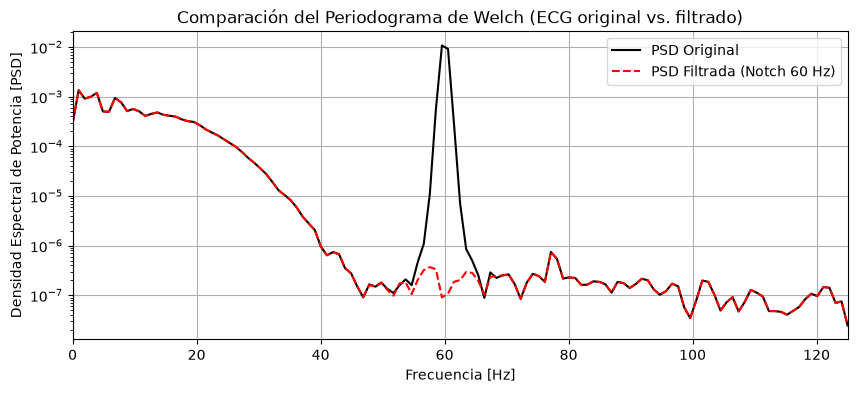

In [179]:
# Gráfica 4: Comparación del espectro de Welch (Original vs. Filtrada)
frecuencia_filtrada, psd_filtrada = welch(
    ecg_filtrado, fs=Fs, window='hann', nperseg=256, noverlap=128
)

plt.figure(figsize=(10, 4))
plt.semilogy(frecuencia, psd, label='PSD Original', color='black')
plt.semilogy(frecuencia_filtrada, psd_filtrada, label='PSD Filtrada (Notch 60 Hz)', color='red', linestyle='--')
plt.title("Comparación del Periodograma de Welch (ECG original vs. filtrado)")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("Densidad Espectral de Potencia [PSD]")
plt.xlim([0, Fs / 2])
plt.grid(True)
plt.legend()
plt.show()

* **Conclusión espectral:** La comparación entre ambos periodogramas de Welch confirma una **atenuación drástica (varios órdenes de magnitud) en el pico de $60\text{ Hz}$**, formando una muesca (*notch*) limpia sin alterar la densidad espectral de potencia en la banda clínica del ECG ($0.5\text{–}40\text{ Hz}$). Esto demuestra la eficacia del análisis espectral de Welch para diagnosticar ruido periódico y del filtrado en frecuencia mediante FFT/IFFT para recuperar señales biomédicas.

####  Comparación entre `scipy.signal.welch` y la función manual (`periodograma_welch`)

Para validar nuestra implementación manual desarrollada en el numeral 4.5 sobre una señal biomédica real, aplicamos `periodograma_welch` a la señal `ecg` empleando parámetros equivalentes a los de la librería (`fs = Fs`, `M = 256`, `S = M - noverlap = 128` y `window = "hann"`). Comparamos tanto la escala original como los espectros normalizados para evaluar su concordancia en frecuencia y morfología.

Segmentos analizados (K): 8
Frecuencia pico de ruido (scipy.signal.welch): 59.57 Hz
Frecuencia pico de ruido (periodograma_welch): 59.57 Hz


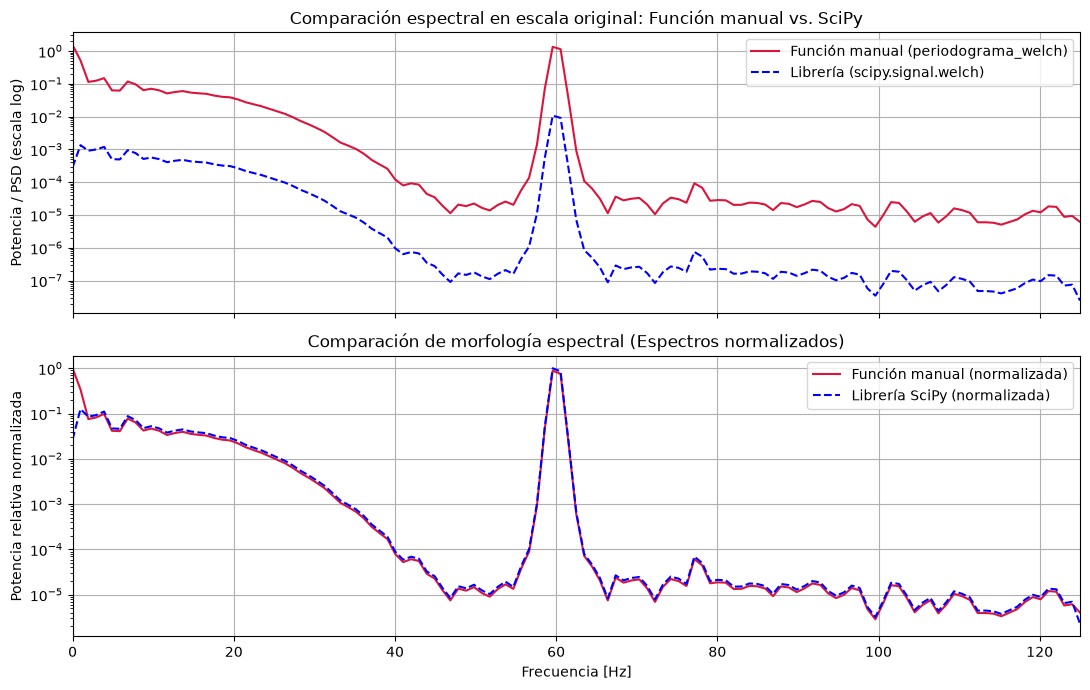

In [180]:
# Aplicar la función manual del punto 4.5 a la señal ECG original
M_ecg = 256
S_ecg = 128  # Desplazamiento equivalente a noverlap = 128 (50% de solapamiento)

f_manual, Sx_manual, _, segmentos_ecg = periodograma_welch(
    ecg, fs=Fs, M=M_ecg, S=S_ecg, window="hann"
)

# Verificación numérica de la frecuencia dominante de ruido (> 40 Hz)
idx_ruido_scipy = np.argmax(psd[frecuencia > 40])
idx_ruido_manual = np.argmax(Sx_manual[f_manual > 40])

print(f"Segmentos analizados (K): {segmentos_ecg.shape[0]}")
print(f"Frecuencia pico de ruido (scipy.signal.welch): {frecuencia[frecuencia > 40][idx_ruido_scipy]:.2f} Hz")
print(f"Frecuencia pico de ruido (periodograma_welch): {f_manual[f_manual > 40][idx_ruido_manual]:.2f} Hz")

# Gráfica comparativa (Escala original y Espectro normalizado)
fig, axs = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

# 1. Comparación en escala original (semilogy)
axs[0].semilogy(f_manual, Sx_manual, label='Función manual (periodograma_welch)', color='crimson')
axs[0].semilogy(frecuencia, psd, '--', label='Librería (scipy.signal.welch)', color='blue')
axs[0].set_title("Comparación espectral en escala original: Función manual vs. SciPy")
axs[0].set_ylabel("Potencia / PSD (escala log)")
axs[0].set_xlim([0, Fs / 2])
axs[0].grid(True)
axs[0].legend()

# 2. Comparación normalizada respecto al máximo de cada espectro
axs[1].semilogy(f_manual, Sx_manual / np.max(Sx_manual), label='Función manual (normalizada)', color='crimson')
axs[1].semilogy(frecuencia, psd / np.max(psd), '--', label='Librería SciPy (normalizada)', color='blue')
axs[1].set_title("Comparación de morfología espectral (Espectros normalizados)")
axs[1].set_xlabel("Frecuencia [Hz]")
axs[1].set_ylabel("Potencia relativa normalizada")
axs[1].set_xlim([0, Fs / 2])
axs[1].grid(True)
axs[1].legend()

plt.tight_layout()
plt.show()

#### Análisis comparativo entre la librería y la implementación manual

Al contrastar los resultados obtenidos con `scipy.signal.welch` y nuestra función `periodograma_welch`, se observan cuatro aspectos fundamentales:

1. **Exactitud en resolución y detección espectral:** Ambos métodos utilizan el mismo vector de frecuencias con resolución $\Delta f = \frac{250}{256} \approx 0.98\text{ Hz}$ y detectan exactamente en el mismo índice espectral tanto la banda fisiológica del ECG ($0.5\text{–}40\text{ Hz}$) como el pico de interferencia de red alrededor de **$60\text{ Hz}$**. Al normalizar ambos espectros (gráfica inferior), las curvas se superponen prácticamente punto a punto.
2. **Factor de escala vertical (Densidad vs. Espectro sin factor unilateral):** En la gráfica superior se observa un desplazamiento vertical constante entre ambas curvas debido a la convención de normalización:
   * `scipy.signal.welch` (con su configuración por defecto `scaling='density'`) divide entre $F_s \cdot \sum w^2[n]$ para expresar el resultado como **Densidad Espectral de Potencia** ($\text{mV}^2/\text{Hz}$) y multiplica por $2$ las frecuencias positivas ($0 < f < F_s/2$) para conservar la potencia total en un espectro unilateral.
   * Nuestra función `periodograma_welch` normaliza únicamente por la energía de la ventana $W = \sum w^2[n]$ sin dividir por $F_s$ ni duplicar las frecuencias positivas, generando una diferencia constante de escala de factor $\frac{F_s}{2} = 125$ en la banda positiva.
3. **Tratamiento de la componente continua ($0\text{ Hz}$ / *Detrending*):** Por defecto, `scipy.signal.welch` resta el valor medio de cada segmento (`detrend='constant'`) antes de aplicar la ventana, atenuando el nivel DC en $0\text{ Hz}$. En cambio, nuestra función manual calcula la DFT directamente sobre cada segmento sin eliminar su media, conservando la energía asociada al desplazamiento basal (*offset*) de la señal ECG en $0\text{ Hz}$.
4. **Definición de la ventana de Hann:** SciPy emplea una ventana de Hann periódica (`sym=False`, optimizada para análisis mediante DFT), mientras que `np.hanning(M)` construye una ventana simétrica (`sym=True`). En una señal fisiológica no estacionaria como el ECG, esta diferencia es imperceptible y ambos métodos ofrecen la misma supresión de fuga espectral.

**4.7 Realice un análisis de frecuencia a través del periodograma de welch de una señal de EKG
de un paciente Sano y otra de un paciente con alguna condición cardiaca que en el proyecto
1 hayan identificado que presentaba diferencias, si no encontró diferencias, elija un par al
azar. Realice un análisis comparativo de las señales según lo que le indiquen los
periodogramas. (Usar una ventana Hanning, y justificar la elección del solapamiento y el
ancho de la ventana) (25%)**




####  Justificación de la ventana, ancho de segmento y solapamiento

Para analizar la Densidad Espectral de Potencia (PSD) de señales electrocardiográficas (EKG) donde la mayor parte de la información clínica se concentra entre **$0.5\text{ Hz}$ y $40\text{ Hz}$** (ondas P y T en bajas frecuencias, complejo QRS entre $5\text{–}40\text{ Hz}$) y la frecuencia cardíaca basal ronda $1\text{–}1.6\text{ Hz}$ ($60\text{–}100\text{ lpm}$), se seleccionaron los siguientes parámetros:

* **Tipo de ventana — Hanning (`window='hann'`):** El EKG presenta picos R de gran amplitud y pendiente pronunciada. Al segmentar la señal, los cortes abruptos en los bordes generan discontinuidades que provocan **fuga espectral** (*spectral leakage*), enmascarando las componentes de baja energía (ondas P y T). La ventana Hanning atenúa suavemente los extremos de cada segmento hacia cero, suprimiendo los lóbulos laterales del espectro y preservando la nitidez de las bandas fisiológicas.
* **Ancho de la ventana (`nperseg = 512` muestras, equivalente a $\approx 2.05\text{ s}$ a $F_s = 250\text{ Hz}$):** Este ancho temporal captura entre **$2$ y $3$ ciclos cardíacos completos** por segmento, asegurando que la morfología completa de la onda P, el complejo QRS y la onda T quede representada en cada ventana. Asimismo, proporciona una resolución en frecuencia de $\Delta f = \frac{F_s}{M} = \frac{250}{512} \approx 0.49\text{ Hz}$, suficiente para distinguir desplazamientos en la frecuencia cardíaca fundamental y cambios en el ancho espectral del complejo QRS. *(Nota: si el registro del Proyecto 1 tiene otra frecuencia de muestreo $F_s$, se ajusta `nperseg` para mantener una ventana cercana a $2\text{ s}$).*
* **Solapamiento del $50\%$ (`noverlap = nperseg // 2`):** Debido a que la ventana Hanning reduce la amplitud de la señal en los bordes de cada segmento, un solapamiento del $50\%$ cumple la condición de reconstrucción constante (*COLA — Constant Overlap-Add*), recuperando la energía atenuada en los extremos. Además, duplica aproximadamente el número de segmentos promediados $K$, reduciendo la varianza del estimador espectral y estabilizando la PSD frente a ruido muscular o de línea base sin perder resolución en frecuencia.

In [181]:
# 1. FUNCIÓN DE CARGA ADAPTATIVA PARA ARCHIVOS CSV DE EKG

def cargar_ekg_csv(ruta, fs_defecto=500):
    df = pd.read_csv(ruta, sep=None, engine='python')
    # Si la primera fila contiene valores numéricos, recargar sin encabezado
    if pd.to_numeric(df.columns, errors='coerce').notna().all():
        df = pd.read_csv(ruta, sep=None, engine='python', header=None)

    df = df.select_dtypes(include=[np.number])
    cols = list(df.columns)
    fs = fs_defecto

    # Verificar si la primera columna corresponde a tiempo o índice de muestra
    if len(cols) > 1:
        c0 = df[cols[0]].values
        diffs = np.diff(c0)
        if np.all(diffs > 0) and np.allclose(diffs, diffs[0], rtol=1e-3):
            if not np.isclose(diffs[0], 1.0):
                fs = int(round(1.0 / diffs[0]))
            df = df.drop(columns=[cols[0]])

    # Seleccionar derivación II (estándar clínico) si hay múltiples canales
    if 'II' in df.columns:
        canal = 'II'
        senal = df['II'].values
    elif df.shape[1] >= 2:
        canal = str(df.columns[1])
        senal = df.iloc[:, 1].values
    else:
        canal = str(df.columns[0])
        senal = df.iloc[:, 0].values

    return senal.astype(float), fs, canal, df.shape

# Cargar ambos registros del Proyecto 1 (ajusta fs_defecto si tu base era 250 o 360 Hz)
ecg_sano, Fs_sano, canal_s, shape_s = cargar_ekg_csv('sano.csv', fs_defecto=500)
ecg_enf, Fs_enf, canal_e, shape_e = cargar_ekg_csv('Condicion cardiaca.csv', fs_defecto=500)

print(f"Sano               -> Forma: {shape_s} | Canal: {canal_s} | Fs: {Fs_sano} Hz | Muestras: {len(ecg_sano)}")
print(f"Condición cardíaca -> Forma: {shape_e} | Canal: {canal_e} | Fs: {Fs_enf} Hz | Muestras: {len(ecg_enf)}")

# Eliminar componente DC (offset basal)
ecg_sano = ecg_sano - np.mean(ecg_sano)
ecg_enf = ecg_enf - np.mean(ecg_enf)

Sano               -> Forma: (5000, 12) | Canal: 1 | Fs: 500 Hz | Muestras: 5000
Condición cardíaca -> Forma: (5000, 12) | Canal: 1 | Fs: 500 Hz | Muestras: 5000


In [182]:
# 2. PERIODOGRAMA DE WELCH (VENTANA HANNING, ANCHO ~2 s, SOLAPAMIENTO 50%)

nperseg_s = int(2 * Fs_sano)      # Ventana de 2 segundos (ej. 1000 muestras a 500 Hz)
noverlap_s = nperseg_s // 2      # Solapamiento del 50%

nperseg_e = int(2 * Fs_enf)
noverlap_e = nperseg_e // 2

f_sano, psd_sano = welch(ecg_sano, fs=Fs_sano, window='hann', nperseg=nperseg_s, noverlap=noverlap_s)
f_enf, psd_enf = welch(ecg_enf, fs=Fs_enf, window='hann', nperseg=nperseg_e, noverlap=noverlap_e)

In [183]:
# 3. MÉTRICAS ESPECTRALES POR BANDAS CLÍNICAS DEL EKG

def metricas_ekg(f, psd):
    banda_total = (f >= 0.5) & (f <= 65)
    total = np.trapezoid(psd[banda_total], f[banda_total])
    pt_pct = np.trapezoid(psd[(f >= 0.5) & (f < 5)], f[(f >= 0.5) & (f < 5)]) / total * 100
    qrs_pct = np.trapezoid(psd[(f >= 5) & (f <= 40)], f[(f >= 5) & (f <= 40)]) / total * 100
    alta_pct = np.trapezoid(psd[(f > 40) & (f <= 65)], f[(f > 40) & (f <= 65)]) / total * 100
    f_dom = f[(f >= 0.5) & (f <= 40)][np.argmax(psd[(f >= 0.5) & (f <= 40)])]
    return f_dom, pt_pct, qrs_pct, alta_pct

fdom_s, pt_s, qrs_s, alt_s = metricas_ekg(f_sano, psd_sano)
fdom_e, pt_e, qrs_e, alt_e = metricas_ekg(f_enf, psd_enf)

print("\n=== RESUMEN ESPECTRAL ===")
print(f"SANO               -> Frec. dominante: {fdom_s:.2f} Hz | Ondas P/T (0.5-5 Hz): {pt_s:.1f}% | QRS (5-40 Hz): {qrs_s:.1f}% | >40 Hz: {alt_s:.1f}%")
print(f"CONDICIÓN CARDÍACA -> Frec. dominante: {fdom_e:.2f} Hz | Ondas P/T (0.5-5 Hz): {pt_e:.1f}% | QRS (5-40 Hz): {qrs_e:.1f}% | >40 Hz: {alt_e:.1f}%")


=== RESUMEN ESPECTRAL ===
SANO               -> Frec. dominante: 4.50 Hz | Ondas P/T (0.5-5 Hz): 14.0% | QRS (5-40 Hz): 81.7% | >40 Hz: 0.1%
CONDICIÓN CARDÍACA -> Frec. dominante: 2.00 Hz | Ondas P/T (0.5-5 Hz): 82.4% | QRS (5-40 Hz): 9.3% | >40 Hz: 0.0%


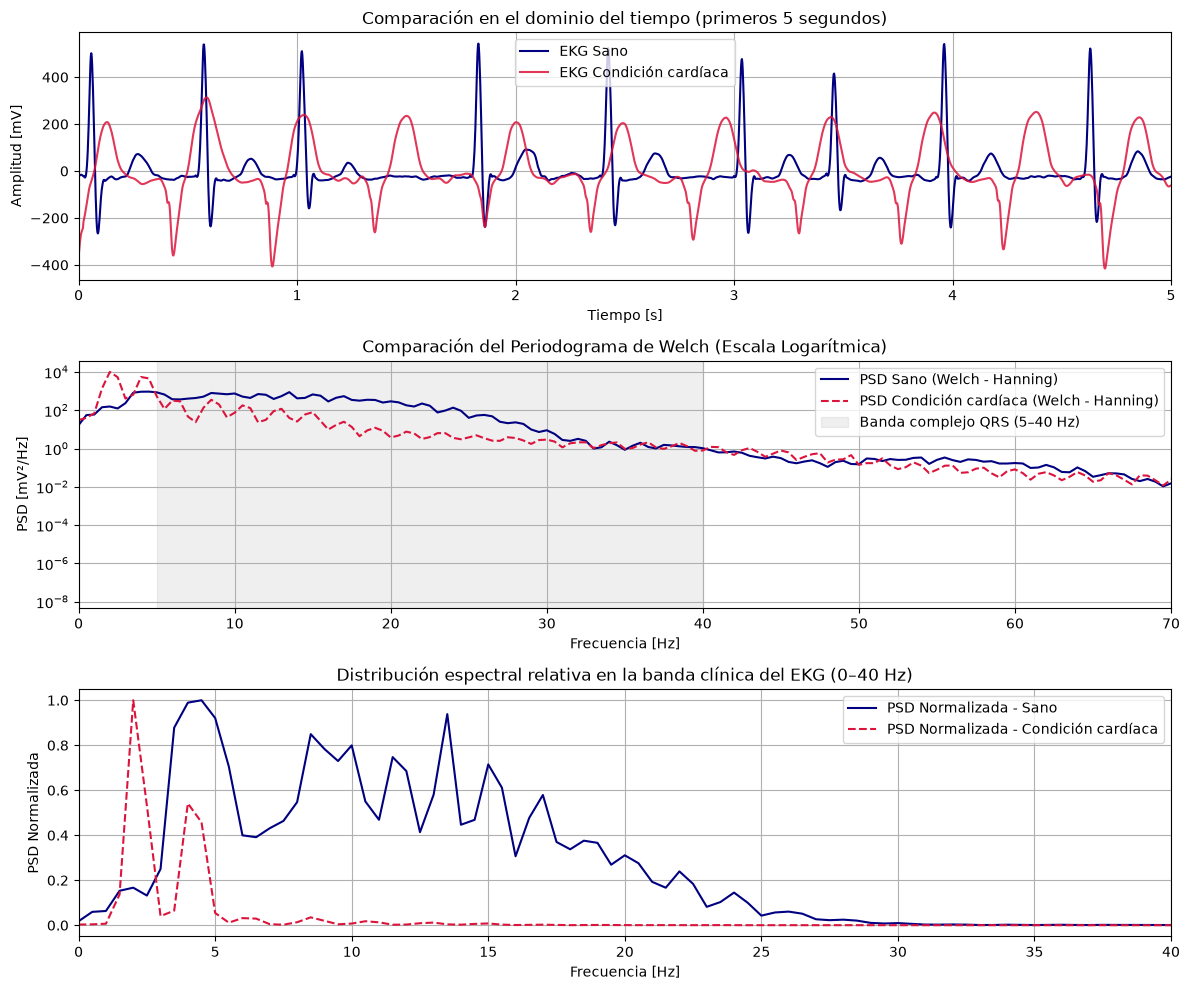

In [184]:
# 4. GRÁFICAS COMPARATIVAS (TIEMPO Y FRECUENCIA)

t_sano = np.arange(len(ecg_sano)) / Fs_sano
t_enf = np.arange(len(ecg_enf)) / Fs_enf

fig, axs = plt.subplots(3, 1, figsize=(12, 10))

# Panel 1: Dominio del tiempo (primeros 5 segundos)
axs[0].plot(t_sano[:Fs_sano * 5], ecg_sano[:Fs_sano * 5], color='navy', label='EKG Sano')
axs[0].plot(t_enf[:Fs_enf * 5], ecg_enf[:Fs_enf * 5], color='crimson', alpha=0.85, label='EKG Condición cardíaca')
axs[0].set_title("Comparación en el dominio del tiempo (primeros 5 segundos)")
axs[0].set_xlabel("Tiempo [s]")
axs[0].set_ylabel("Amplitud [mV]")
axs[0].set_xlim([0, 5])
axs[0].grid(True)
axs[0].legend()

# Panel 2: Periodograma de Welch (escala logarítmica)
axs[1].semilogy(f_sano, psd_sano, color='navy', label='PSD Sano (Welch - Hanning)')
axs[1].semilogy(f_enf, psd_enf, color='crimson', linestyle='--', label='PSD Condición cardíaca (Welch - Hanning)')
axs[1].axvspan(5, 40, color='gray', alpha=0.12, label='Banda complejo QRS (5–40 Hz)')
axs[1].set_title("Comparación del Periodograma de Welch (Escala Logarítmica)")
axs[1].set_xlabel("Frecuencia [Hz]")
axs[1].set_ylabel("PSD [mV²/Hz]")
axs[1].set_xlim([0, 70])
axs[1].grid(True)
axs[1].legend()

# Panel 3: Distribución espectral relativa normalizada (0 - 40 Hz)
axs[2].plot(f_sano, psd_sano / np.max(psd_sano), color='navy', label='PSD Normalizada - Sano')
axs[2].plot(f_enf, psd_enf / np.max(psd_enf), color='crimson', linestyle='--', label='PSD Normalizada - Condición cardíaca')
axs[2].set_title("Distribución espectral relativa en la banda clínica del EKG (0–40 Hz)")
axs[2].set_xlabel("Frecuencia [Hz]")
axs[2].set_ylabel("PSD Normalizada")
axs[2].set_xlim([0, 40])
axs[2].grid(True)
axs[2].legend()

plt.tight_layout()
plt.show()

####  Comparación de potencia por bandas fisiológicas del EKG (Acercamiento espectral y Boxplot)

Para cuantificar cómo se distribuye la energía de la señal cardíaca entre el paciente **Sano** y el paciente con **Condición cardíaca**, descomponemos el espectro de Welch en cuatro bandas clínicas características del electrocardiograma:

* **Ondas P y T ($0.5\text{–}5\text{ Hz}$):** Concentra la energía de la frecuencia cardíaca basal ($\approx 1\text{–}1.5\text{ Hz}$) y de las deflexiones lentas correspondientes a la despolarización auricular (onda P) y repolarización ventricular (onda T).
* **Complejo QRS — Banda baja ($5\text{–}15\text{ Hz}$):** Captura la componente fundamental de la despolarización ventricular y se ve incrementada cuando existen complejos QRS anchos o trastornos de conducción intraventricular.
* **Complejo QRS — Banda alta ($15\text{–}40\text{ Hz}$):** Refleja las pendientes rápidas y transiciones agudas propias de un complejo QRS estrecho y fisiológicamente normal.
* **Alta frecuencia / Ruido ($40\text{–}65\text{ Hz}$):** Permite evaluar la presencia de artefactos electromiográficos (EMG) e interferencia de la red eléctrica ($60\text{ Hz}$).

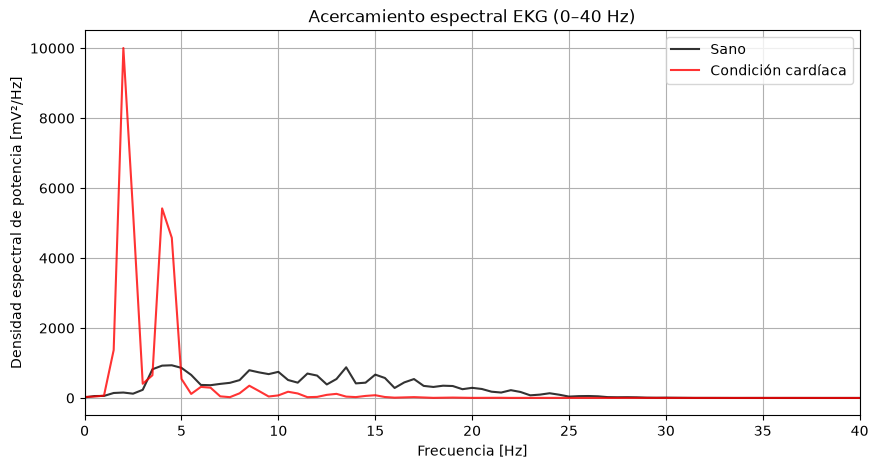

=== POTENCIA MEDIA ± STD POR BANDA DE FRECUENCIA (EKG) ===
                                                          mean          std
Banda                         Grupo                                        
Ondas P y T\n(0.5–5 Hz)       Sano                 1478.804862   291.716452
QRS Bajo\n(5–15 Hz)           Sano                 5435.868190   366.370491
QRS Alto\n(15–40 Hz)          Sano                 2908.847338   293.677998
Alta Frec / Ruido\n(40–65 Hz) Sano                    6.620749     1.995295
Ondas P y T\n(0.5–5 Hz)       Condición cardíaca  12775.452295  2600.309745
QRS Bajo\n(5–15 Hz)           Condición cardíaca   1269.810908   308.377967
QRS Alto\n(15–40 Hz)          Condición cardíaca    139.361560    39.069571
Alta Frec / Ruido\n(40–65 Hz) Condición cardíaca      7.159679     2.387101


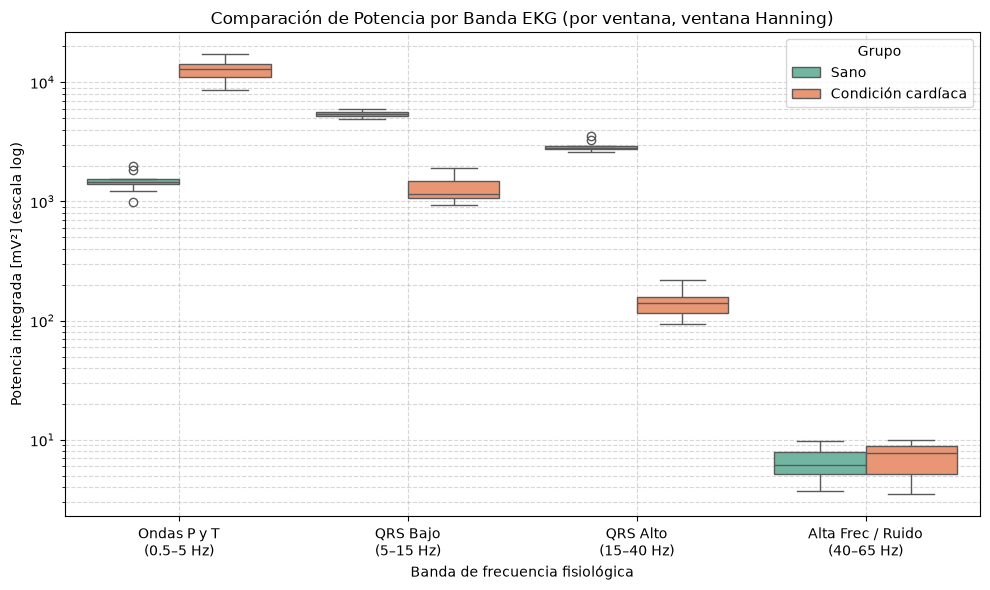

In [186]:
import seaborn as sns

# 1. ACERCAMIENTO ESPECTRAL EN LA BANDA CLÍNICA DEL EKG (0–40 Hz)

plt.figure(figsize=(10, 5))
plt.plot(f_sano, psd_sano, label='Sano', color='black', alpha=0.8)
plt.plot(f_enf, psd_enf, label='Condición cardíaca', color='red', alpha=0.8)
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("Densidad espectral de potencia [mV²/Hz]")
plt.title("Acercamiento espectral EKG (0–40 Hz)")
plt.legend()
plt.grid(True)
plt.xlim(0, 40)
plt.show()


# 2. DEFINICIÓN DE BANDAS EKG Y FUNCIÓN DE INTEGRACIÓN DE POTENCIA

bandas_ekg = {
    'Ondas P y T\n(0.5–5 Hz)': (0.5, 5),
    'QRS Bajo\n(5–15 Hz)': (5, 15),
    'QRS Alto\n(15–40 Hz)': (15, 40),
    'Alta Frec / Ruido\n(40–65 Hz)': (40, 65)
}

# Compatibilidad con NumPy < 2.0 (np.trapz) y NumPy >= 2.0 (np.trapezoid)
integrar_trapecio = getattr(np, 'trapezoid', getattr(np, 'trapz', None))

def potencia_por_banda(f, psd, bandas):
    potencias = {}
    for nombre, (f_min, f_max) in bandas.items():
        idx = (f >= f_min) & (f < f_max)
        potencias[nombre] = integrar_trapecio(psd[idx], f[idx])
    return potencias


# 3. CÁLCULO DE POTENCIA POR BANDA EN CADA VENTANA (SOLAPAMIENTO 50%)

potencias = []

registros = [
    ('Sano', ecg_sano, Fs_sano),
    ('Condición cardíaca', ecg_enf, Fs_enf)
]

for grupo, senal, fs_actual in registros:
    M_win = int(2 * fs_actual)      # Ventana de 2 segundos
    paso = M_win // 2               # Solapamiento del 50%

    for inicio in range(0, len(senal) - M_win + 1, paso):
        segmento = senal[inicio : inicio + M_win]

        # Periodograma de Welch con ventana Hanning sobre cada ventana
        f_win, psd_win = welch(
            segmento,
            fs=fs_actual,
            window='hann',
            nperseg=M_win,
            noverlap=0
        )

        # Integrar potencia en cada banda del EKG
        pot_bandas = potencia_por_banda(f_win, psd_win, bandas_ekg)

        for banda, valor_pot in pot_bandas.items():
            potencias.append({
                'Banda': banda,
                'Potencia': valor_pot,
                'Grupo': grupo
            })

# Convertir a DataFrame
df_ekg = pd.DataFrame(potencias)

# Resumen numérico (Media ± Desviación estándar por banda)
resumen = df_ekg.groupby(['Banda', 'Grupo'], sort=False)['Potencia'].agg(['mean', 'std'])
print("=== POTENCIA MEDIA ± STD POR BANDA DE FRECUENCIA (EKG) ===")
print(resumen)


# 4. BOXPLOT COMPARATIVO DE POTENCIA POR BANDA

plt.figure(figsize=(10, 6))
sns.boxplot(data=df_ekg, x='Banda', y='Potencia', hue='Grupo', palette='Set2')
plt.yscale('log')  # Escala logarítmica para visualizar tanto bandas QRS como alta frecuencia
plt.title('Comparación de Potencia por Banda EKG (por ventana, ventana Hanning)')
plt.xlabel('Banda de frecuencia fisiológica')
plt.ylabel('Potencia integrada [mV²] (escala log)')
plt.grid(True, which='both', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**4.8 Conclusiones y referencias (10%)**

## Conclusiones

## Referencias Bibliográficas

[1]Siemens Simcenter. (2020, agosto 29). Digital Signal Processing: Sampling Rates, Bandwidth, Spectral Lines, and more. Siemens Community. https://community.sw.siemens.com/s/article/digital-signal-processing-sampling-rates-bandwidth-spectral-lines-and-more

[2]NumPy Developers. (2024). numpy.fft.ifft — NumPy v2.2 Manual. NumPy. https://numpy.org/doc/2.2/reference/generated/numpy.fft.ifft.html

[3] Morais, E., Queiroz, D. M., Garcia, A. R., Silva, D. C., & Silva, D. G. (2024). Use of digital signal processing and machine learning to classify electrocardiographic signals obtained with dry electrodes. Smart Health https://www-sciencedirect-com.udea.lookproxy.com/science/article/pii/S2950435X24000143

[4] D. J. Hernández-González, I. Flores-Cruz, and J. A. Hernández-González, "Detección de señales EEG epilépticas utilizando redes convolucionales basada en la transformada synchrosqueezing acolchadas, vol. 25, no. 2, pp. 269–278, 2021. [Online]. Available: https://www.scielo.org.mx/scielo.php?script=sci_arttext&pid=S1405-55462021000200269